[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leidyomuete/modelo-insolvencia-pymes/blob/main/Modelo_insolvencia_Colab.ipynb)

# Modelo predictivo para la identificación temprana del riesgo de insolvencia empresarial
### Empresas colombianas de los sectores manufacturero y comercial (Pymes, Grupo 2 NIIF, 2016–2025)

**Autora:** Leidy Briggitte Muete Garzón · **Tutora:** Gabriela María Saucedo Meza, Ph.D.
Maestría en Analítica de Datos para Contabilidad y Auditoría — Universidad Externado de Colombia

Este cuaderno ejecuta, paso a paso y sin instalar nada en el computador, el modelo descrito en el documento de investigación:
Random Forest complementado con SMOTE y contrastado con una regresión logística, con horizonte de predicción de tres años.

---
#### Cómo usarlo
1. Deje la fuente en **GitHub** (no requiere nada más) o elija **Google Drive** o **Google Drive** (la carpeta **Proyecto_Insolvencia**
   compartida por la autora debe aparecer en su Drive; si la recibió como enlace: clic derecho → *Organizar* → *Agregar acceso directo* → *Mi unidad*).
2. En el menú superior elija **Entorno de ejecución → Ejecutar todas** (o `Ctrl + F9`).
3. Si usa Google Drive, autorice el acceso cuando Colab lo solicite.

| Modo | Tiempo aproximado |
|---|---|
| Base consolidada + entrenamiento rápido | 8–12 minutos |
| Base consolidada + entrenamiento completo (como en la tesis) | 30–45 minutos |
| Excel originales del SIIS + entrenamiento completo | 45–60 minutos |

Los resultados se guardan en `modelo_insolvencia/resultados_colab` dentro de la carpeta del proyecto.

In [15]:
#@title 1. Configuración { display-mode: "form" }
#@markdown **Origen del código y de la base consolidada.** Con GitHub no se necesita Google Drive.
FUENTE = "GitHub"  #@param ["GitHub", "Google Drive"]
REPO_GITHUB = "https://github.com/leidyomuete/modelo-insolvencia-pymes"  #@param {type:"string"}
#@markdown Ruta de la carpeta del proyecto en Google Drive (solo si FUENTE = Google Drive o si usa los Excel originales):
CARPETA_PROYECTO = "/content/drive/MyDrive/Proyecto_Insolvencia"  #@param {type:"string"}
#@markdown Origen de los datos: la base consolidada (11 MB) reproduce exactamente la depuración de los 40 archivos Excel del SIIS.
MODO_DATOS = "Base consolidada (rápido)"  #@param ["Base consolidada (rápido)", "Excel SIIS originales (lento)"]
#@markdown Entrenamiento: el modo completo usa la misma búsqueda de hiperparámetros que la tesis (20 combinaciones, 5 pliegues).
MODO_ENTRENAMIENTO = "Rápido"  #@param ["Rápido", "Completo (como en la tesis)"]
#@markdown Definición de insolvencia (la del documento es la oficial; las otras son análisis de sensibilidad):
REGLA_ETIQUETA = "documento"  #@param ["documento", "estricta", "formal"]

In [16]:
#@title 2. Obtener el código y verificar archivos
import os, sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
necesita_drive = FUENTE == "Google Drive" or not MODO_DATOS.startswith("Base")
if EN_COLAB and necesita_drive:
    from google.colab import drive
    drive.mount("/content/drive")

RAIZ = Path(CARPETA_PROYECTO)
BD = RAIZ / "bd"
if FUENTE == "GitHub":
    destino = Path("/content/repo_insolvencia") if EN_COLAB else Path("/tmp/repo_insolvencia")
    if not destino.exists():
        subprocess.run(["git", "clone", "-q", REPO_GITHUB.strip(), str(destino)], check=True)
    else:
        subprocess.run(["git", "-C", str(destino), "pull", "-q"], check=False)
    CODIGO = next(destino.rglob("main.py")).parent      # funciona si el código está en la raíz o en una subcarpeta
    # Si los archivos se subieron sin las carpetas src/ y data/, se reorganizan aquí
    for carpeta, archivos in {"src": ["__init__.py", "carga.py", "macro.py", "modelado.py", "reporte.py", "variables.py"],
                              "data": ["macro_colombia.csv", "panel_consolidado.parquet"]}.items():
        (CODIGO / carpeta).mkdir(exist_ok=True)
        for a in archivos:
            if (CODIGO / a).exists() and not (CODIGO / carpeta / a).exists():
                (CODIGO / a).rename(CODIGO / carpeta / a)
    (CODIGO / "src" / "__init__.py").touch()
else:
    CODIGO = RAIZ / "modelo_insolvencia"

def verificar(ruta, descripcion):
    estado = "OK " if ruta.exists() else "FALTA"
    print(f"[{estado}] {descripcion}: {ruta}")
    return ruta.exists()

ok = verificar(CODIGO / "main.py", "Código del modelo")
ok &= verificar(CODIGO / "data" / "macro_colombia.csv", "Variables macroeconómicas")
if MODO_DATOS.startswith("Base"):
    ok &= verificar(CODIGO / "data" / "panel_consolidado.parquet", "Base consolidada")
else:
    ok &= verificar(BD / "pymes_individuales-2016", "Carpeta bd con los Excel del SIIS")
if not ok:
    raise FileNotFoundError("Revise la ruta CARPETA_PROYECTO del paso 1 o que la carpeta compartida esté en su Drive.")

[OK ] Código del modelo: /content/repo_insolvencia/main.py
[OK ] Variables macroeconómicas: /content/repo_insolvencia/data/macro_colombia.csv
[OK ] Base consolidada: /content/repo_insolvencia/data/panel_consolidado.parquet


In [17]:
#@title 3. Instalar librerías (solo las que no trae Colab)
!pip install -q imbalanced-learn shap python-calamine

In [18]:
#@title 4. Cargar el código y los parámetros metodológicos
import importlib, warnings
import pandas as pd
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

os.chdir(CODIGO)
if str(CODIGO) not in sys.path:
    sys.path.insert(0, str(CODIGO))
import config as cfg
importlib.reload(cfg)

cfg.RUTA_BD = BD
cfg.RUTA_RESULTADOS = CODIGO / "resultados_colab"
cfg.RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
cfg.REGLA_ETIQUETA = REGLA_ETIQUETA
if MODO_ENTRENAMIENTO == "Rápido":
    cfg.N_ITER_BUSQUEDA, cfg.N_FOLDS_CV, cfg.N_BOOTSTRAP = 5, 3, 300

from src import carga, variables, modelado, reporte, macro
for m in (carga, variables, modelado, reporte, macro):
    importlib.reload(m)

pd.DataFrame({
    "Parámetro": ["Sectores (CIIU Rev. 4 A.C.)", "Años", "Horizonte de predicción", "Regla de etiqueta",
                  "Estados de insolvencia formal", "Partición", "Validación cruzada", "Combinaciones de hiperparámetros",
                  "Validación fuera de tiempo", "Niveles de riesgo"],
    "Valor": ["C (manufactura) y G (comercio)", f"{cfg.ANIOS[0]}–{cfg.ANIOS[-1]}", f"{cfg.HORIZONTE} años (t+1 a t+3)",
              cfg.REGLA_ETIQUETA, ", ".join(cfg.ESTADOS_INSOLVENCIA_FORMAL),
              f"{int((1-cfg.PROPORCION_PRUEBA)*100)} % / {int(cfg.PROPORCION_PRUEBA*100)} % por empresa",
              f"{cfg.N_FOLDS_CV} pliegues estratificados por empresa", cfg.N_ITER_BUSQUEDA,
              f"entrena ≤ {cfg.ANIO_CORTE_OOT}, prueba > {cfg.ANIO_CORTE_OOT}",
              "; ".join(f"{k}: {a:.0%}–{min(b,1):.0%}" for k, (a, b) in cfg.UMBRALES_RIESGO.items())],
}).style.hide(axis="index")

Parámetro,Valor
Sectores (CIIU Rev. 4 A.C.),C (manufactura) y G (comercio)
Años,2016–2025
Horizonte de predicción,3 años (t+1 a t+3)
Regla de etiqueta,documento
Estados de insolvencia formal,"ACUERDO DE REORGANIZACION, ACUERDO DE REESTRUCTURACION, CONCORDATO EN EJECUCION, CONCORDATO EN TRAMITE"
Partición,70 % / 30 % por empresa
Validación cruzada,3 pliegues estratificados por empresa
Combinaciones de hiperparámetros,5
Validación fuera de tiempo,"entrena ≤ 2020, prueba > 2020"
Niveles de riesgo,Bajo: 0%–30%; Medio: 30%–60%; Alto: 60%–100%


## Paso 1. Carga y depuración de los estados financieros
Se leen los reportes del SIIS de la Superintendencia de Sociedades (carátula, estado de situación financiera, estado de resultado integral y estado de flujos de efectivo),
se filtran las secciones CIIU C y G, los cortes al 31 de diciembre y los registros con ecuación patrimonial consistente.

In [19]:
#@title 5. Construir el panel empresa-año
import time
t0 = time.time()
if MODO_DATOS.startswith("Base"):
    panel = pd.read_parquet(CODIGO / "data" / "panel_consolidado.parquet")
    print(f"Base consolidada cargada: {len(panel):,} estados financieros de {panel.nit.nunique():,} empresas")
else:
    macro.construir_macro()          # lee las series del Banco de la República de la carpeta bd
    panel = carga.construir_panel()  # lee los 40 archivos Excel del SIIS (~15 min)

resumen = panel.pivot_table(index="anio", columns="sector", values="nit", aggfunc="count", margins=True, margins_name="Total")
print(f"Tiempo: {(time.time()-t0)/60:.1f} min")
resumen

Base consolidada cargada: 82,108 estados financieros de 15,009 empresas
Tiempo: 0.0 min


sector,Comercial,Manufacturero,Total
anio,,,
2016,4821,2702,7523
2017,3853,2109,5962
2018,3850,1927,5777
2019,5340,2612,7952
2020,5961,3006,8967
2021,5824,2974,8798
2022,6150,3115,9265
2023,6381,3148,9529
2024,6017,3021,9038


In [20]:
#@title 6. Variables macroeconómicas utilizadas (Banco de la República / DANE)
pd.read_csv(cfg.RUTA_MACRO).set_index("anio")

,tasa_banrep,inflacion,crec_pib,crec_pib_manufactura,crec_pib_comercio,trm_promedio
anio,,,,,,
2016,7.5000,5.7500,2.0900,3.2200,3.6200,3050.9800
2017,4.7500,4.0900,1.3600,-1.8200,1.6100,2951.3200
2018,4.2500,3.1800,2.5600,1.4800,2.8000,2956.4300
2019,4.2500,3.8000,3.1900,1.2000,4.0400,3281.0900
2020,1.7500,1.6100,-7.1900,-9.2500,-3.7000,3693.3600
2021,3.0000,5.6200,10.8000,13.5900,15.4500,3743.0900
2022,12.0000,13.1200,7.3300,8.1600,6.7800,4255.4400
2023,13.0000,9.2800,0.8400,-1.6200,-5.0700,4325.0500
2024,9.5000,5.2000,1.4900,-2.5600,0.5700,4071.3500


## Paso 2. Indicadores financieros y variable dependiente
Se calculan los indicadores de la Tabla 1 (y las variables complementarias del Anexo 1) y se etiqueta cada observación del año *t*
como **en riesgo (y = 1)** si en alguno de los años *t+1, t+2 o t+3* cumple al menos un criterio de la definición operacional:
proceso formal (Ley 1116), patrimonio negativo, EBITDA negativo, razón corriente < 1 o cobertura de intereses < 1.

In [21]:
#@title 7. Construir la base de modelado
import matplotlib.pyplot as plt
panel_ind, base = variables.construir_base_modelado(panel)
cols = variables.columnas_modelo()

crit = [c for c in panel_ind.columns if c.startswith("crit_")]
nombres = {"crit_ley1116": "Proceso formal (Ley 1116)", "crit_patrimonio_neg": "Patrimonio negativo",
           "crit_ebitda_neg": "EBITDA negativo", "crit_rc_menor1": "Razón corriente < 1",
           "crit_cobertura_menor1": "Cobertura de intereses < 1"}
prev = (panel_ind.groupby("sector")[crit].mean() * 100).rename(columns=nombres).T.round(1)
print("Frecuencia de cada criterio (% de estados financieros, 2016-2025):")
display(prev)

fig, ax = plt.subplots(figsize=(8, 3.5))
(base.groupby(["anio", "sector"]).y.mean().unstack() * 100).plot(ax=ax, marker="o")
ax.set_ylabel("% de empresas en riesgo"); ax.set_xlabel("Año de los estados financieros (t)")
ax.set_title("Proporción de empresas que presentan el evento en t+1 a t+3"); ax.grid(alpha=.3)
plt.show()
print(f"Observaciones para el modelo: {len(base):,}  |  variables explicativas: {len(cols)}")

  Observaciones etiquetadas: 49,289 -> 46,810 tras exclusiones
  Proporción de empresas en riesgo (y=1): 39.2%
Frecuencia de cada criterio (% de estados financieros, 2016-2025):


sector,Comercial,Manufacturero
Proceso formal (Ley 1116),4.0000,8.4000
Patrimonio negativo,4.2000,4.7000
EBITDA negativo,12.4000,12.7000
Razón corriente < 1,11.0000,15.9000
Cobertura de intereses < 1,13.9000,15.2000


Observaciones para el modelo: 46,810  |  variables explicativas: 20


## Paso 3. Entrenamiento y evaluación (70 % / 30 %)
Ambos modelos usan la misma secuencia: winsorización → imputación por la mediana → **SMOTE (solo en entrenamiento)** → modelo.
La partición se hace por empresa, de modo que una misma sociedad nunca aparece a la vez en entrenamiento y en prueba.

In [8]:
#@title 8. Entrenar Random Forest + SMOTE y regresión logística + SMOTE
from IPython.display import Image, display
t0 = time.time()
rf, lr, metricas, importancia = modelado.evaluar_y_comparar(base, cols)
print(f"\nTiempo de entrenamiento: {(time.time()-t0)/60:.1f} min")

  Entrenamiento: 32,510 obs. (39.3% en riesgo) | Prueba: 14,300 obs. (38.9% en riesgo)
  Random Forest + SMOTE: AUC validación cruzada = 0.8098
    mejores hiperparámetros: {'smote__k_neighbors': 5, 'modelo__n_estimators': 500, 'modelo__min_samples_leaf': 50, 'modelo__max_features': 0.3, 'modelo__max_depth': None}
  Regresión logística + SMOTE: AUC validación cruzada = 0.7599
    mejores hiperparámetros: {'smote__k_neighbors': 5, 'modelo__C': np.float64(0.1873817422860383)}

  Métricas en prueba (umbral 0,5):
                      Random Forest + SMOTE  Regresión logística + SMOTE
exactitud                           0.7403                       0.6950
precision                           0.6619                       0.5965
sensibilidad_recall                 0.6802                       0.6685
especificidad                       0.7786                       0.7118
f1                                  0.6709                       0.6305
auc_roc                             0.8063          

,Random Forest + SMOTE,Regresión logística + SMOTE
Exactitud,0.7400,0.6950
Precisión,0.6620,0.5970
Sensibilidad (recall),0.6800,0.6690
Especificidad,0.7790,0.7120
F1-score,0.6710,0.6300
AUC-ROC,0.8060,0.7590
AUC-PR,0.7500,0.6980
Puntaje de Brier,0.1760,0.1970


Diferencia de AUC (RF - Logit): IC 95 % = [0.043; 0.053]  -> el Random Forest SUPERA a la regresión logística (cumple BRS-03)


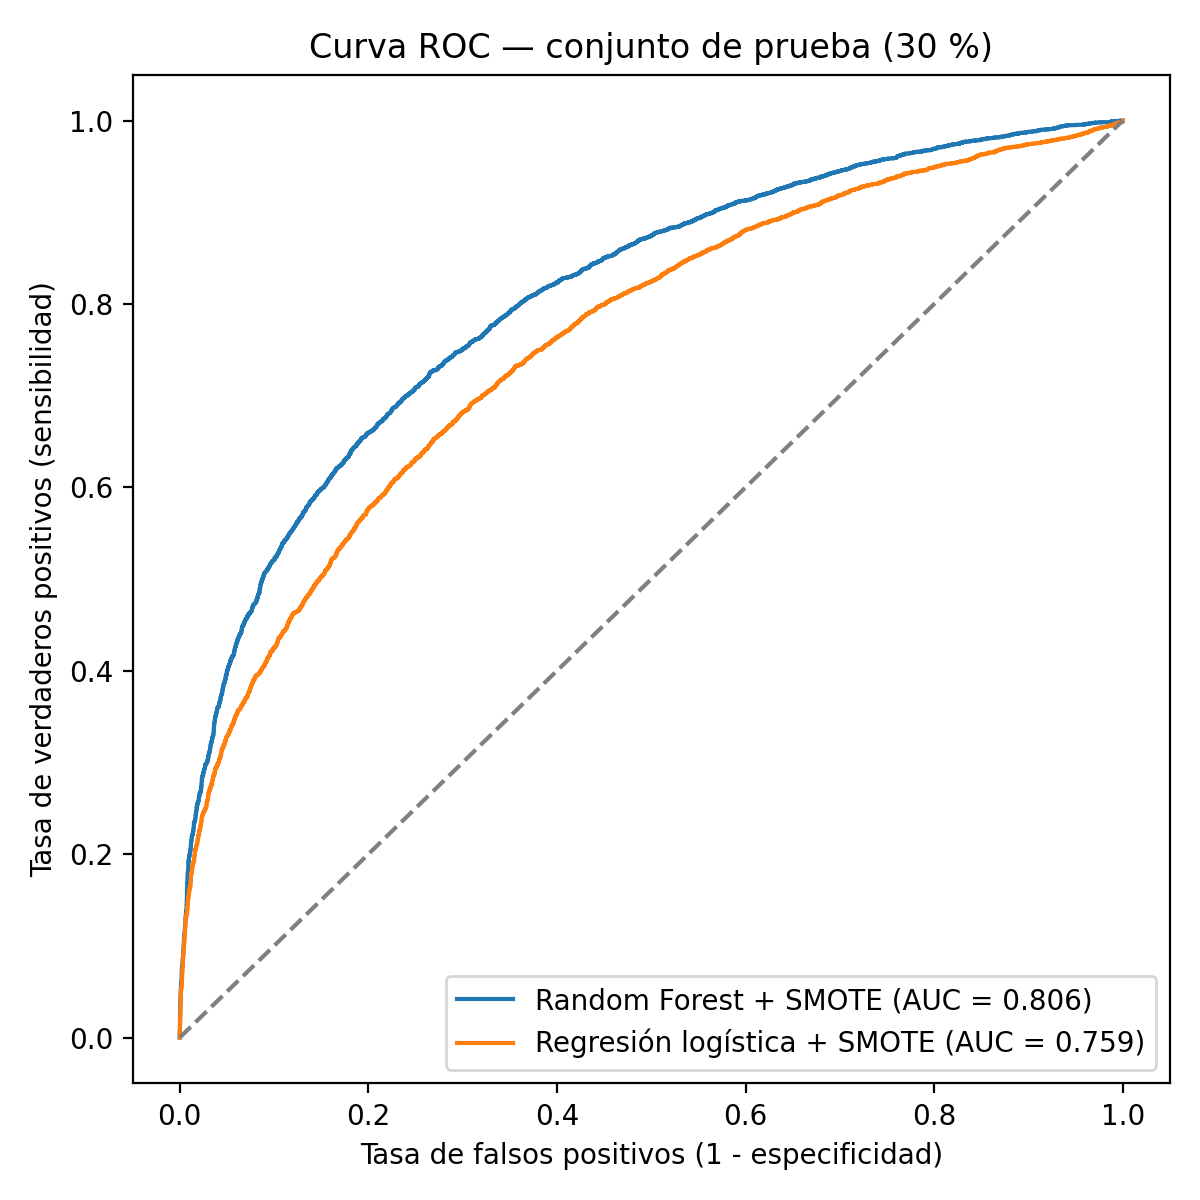

In [9]:
#@title 9. Resultados en el conjunto de prueba
import json
comp = json.load(open(cfg.RUTA_RESULTADOS / "03_comparacion_modelos.json"))
tabla = metricas.drop(["VP", "FP", "FN", "VN"]).rename(index={
    "exactitud": "Exactitud", "precision": "Precisión", "sensibilidad_recall": "Sensibilidad (recall)",
    "especificidad": "Especificidad", "f1": "F1-score", "auc_roc": "AUC-ROC", "auc_pr": "AUC-PR", "brier": "Puntaje de Brier"})
display(tabla.round(3))
a, b = comp["IC95_diferencia"]
print(f"Diferencia de AUC (RF - Logit): IC 95 % = [{a:.3f}; {b:.3f}]  ->",
      "el Random Forest SUPERA a la regresión logística (cumple BRS-03)" if a > 0 else "no hay diferencia significativa")
display(Image(str(cfg.RUTA_RESULTADOS / "03_curva_roc.png"), width=480))

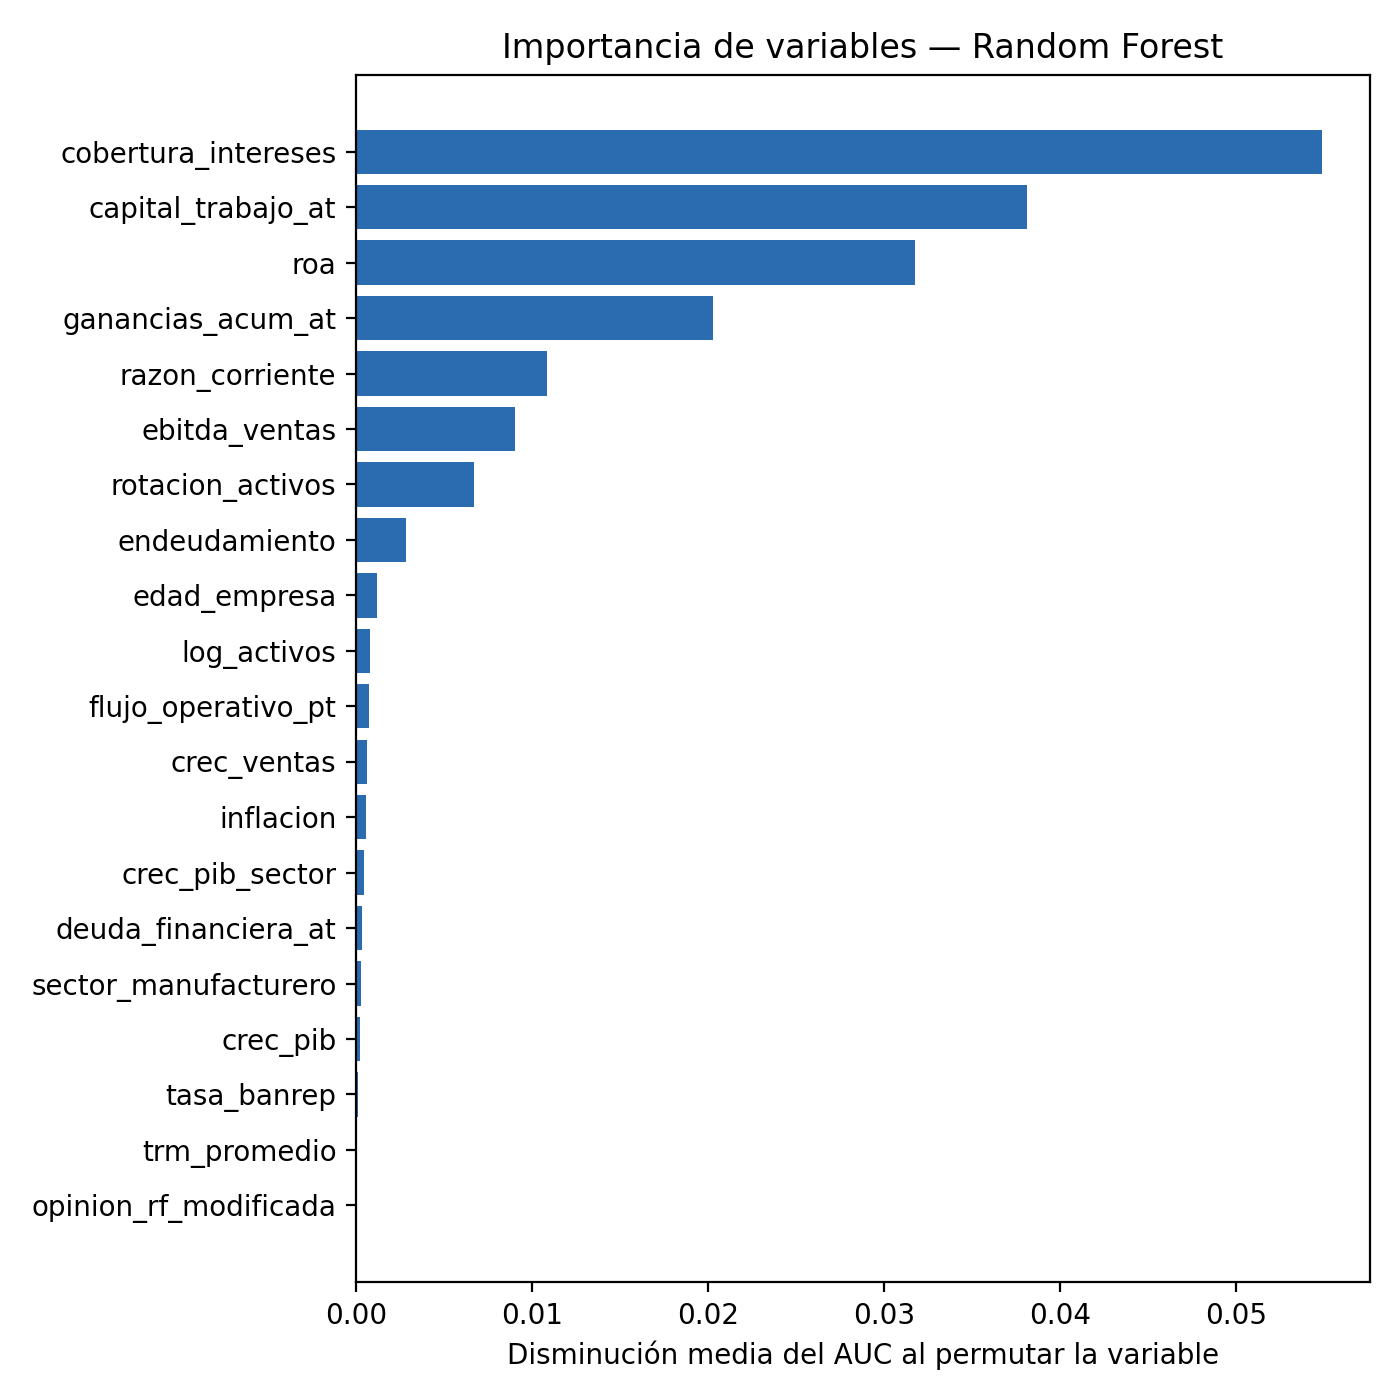

,variable,importancia_gini_rf,importancia_permutacion_rf,coef_logit_estandarizado,odds_ratio_logit
3,Cobertura de intereses,0.1794,0.0549,-0.1063,0.8991
4,Capital de trabajo / Activo,0.1784,0.0381,-0.6624,0.5156
2,Rentabilidad del activo (ROA),0.2107,0.0318,-0.4748,0.6220
13,Ganancias acumuladas / Activo,0.0868,0.0203,-0.3505,0.7043
0,Razón corriente,0.1124,0.0109,0.2947,1.3427
5,Margen EBITDA,0.0526,0.0090,-0.1109,0.8950
6,Rotación de activos,0.0267,0.0067,-0.0619,0.9400
1,Endeudamiento total,0.0381,0.0029,0.0654,1.0676
16,Edad de la empresa,0.0171,0.0012,-0.0877,0.9160
11,Tamaño (log activos),0.0175,0.0008,-0.0320,0.9685


In [10]:
#@title 10. Importancia de las variables
display(Image(str(cfg.RUTA_RESULTADOS / "03_importancia_variables.png"), width=620))
importancia.assign(variable=importancia.variable.map(lambda c: reporte.NOMBRES.get(c, c))).head(10).round(4)

In [11]:
#@title 11. Desempeño por sector y validación fuera de tiempo
display(pd.read_csv(cfg.RUTA_RESULTADOS / "03_metricas_por_sector.csv", index_col=0).round(3))
oot = modelado.validacion_fuera_de_tiempo(base, cols, rf, lr)

,n,tasa_riesgo,auc_rf,auc_logit
sector,,,,
Comercial,9661.0000,0.3810,0.8090,0.7620
Manufacturero,4639.0000,0.4070,0.8000,0.7540



  Validación fuera de tiempo (entrena <= 2020, prueba > 2020):
                      Random Forest + SMOTE  Regresión logística + SMOTE
exactitud                           0.7562                       0.7059
precision                           0.7291                       0.6360
sensibilidad_recall                 0.5864                       0.5572
especificidad                       0.8630                       0.7995
f1                                  0.6500                       0.5940
auc_roc                             0.8052                       0.7449
auc_pr                              0.7530                       0.6878
brier                               0.1689                       0.1937
VP                               3637.0000                    3456.0000
FP                               1351.0000                    1978.0000
FN                               2565.0000                    2746.0000
VN                               8512.0000                    7885.0000

## Paso 4. Calificación de empresas y reporte para el usuario
Se califican las empresas con estados financieros del último año disponible (2025): probabilidad de presentar insolvencia entre 2026 y 2028,
nivel de riesgo y los tres indicadores que más elevan su riesgo (valores SHAP).

In [12]:
#@title 12. Generar el reporte
calificacion = reporte.calificar_empresas(panel_ind, rf, cols)
ruta_excel = reporte.exportar(calificacion, metricas, importancia)
reporte.guardar_modelo(rf, cols)

display(pd.crosstab(calificacion.sector, calificacion.nivel_riesgo, margins=True, margins_name="Total")
          [["Bajo", "Medio", "Alto", "Total"]])
print("\n20 empresas con mayor probabilidad de riesgo:")
calificacion.head(20)[["nit", "razon_social", "sector", "probabilidad_riesgo", "nivel_riesgo", "principales_factores"]]

  Reporte guardado en: /content/repo_insolvencia/resultados_colab/05_reporte_riesgo_insolvencia.xlsx


nivel_riesgo,Bajo,Medio,Alto,Total
sector,,,,
Comercial,2270,2026,1964,6260
Manufacturero,966,956,1115,3037
Total,3236,2982,3079,9297



20 empresas con mayor probabilidad de riesgo:


,nit,razon_social,sector,probabilidad_riesgo,nivel_riesgo,principales_factores
26006,830058340,PROMOTORA COLOMBIANA DE GAS GNV S A,Comercial,0.9886,Alto,"Capital de trabajo / Activo, Rentabilidad del ..."
75327,900770234,TAGGO COMPANY S.A.S.,Comercial,0.9885,Alto,"Capital de trabajo / Activo, Rentabilidad del ..."
71711,900593026,CRISTALES TEMPLSDOS LA TORRE SAS-EN REORGANIZA...,Manufacturero,0.9883,Alto,"Capital de trabajo / Activo, Rentabilidad del ..."
76521,900856018,SPORT CENTER S.A.S,Comercial,0.9877,Alto,"Capital de trabajo / Activo, Rentabilidad del ..."
74967,900741561,ONA FOODS SAS,Comercial,0.9871,Alto,"Capital de trabajo / Activo, Rentabilidad del ..."
10002,800225074,LATIN PRODUCTS SAS,Manufacturero,0.9861,Alto,"Capital de trabajo / Activo, Rentabilidad del ..."
28142,830086971,JAWOOD SUPPLIERS Y CIA SAS,Comercial,0.9857,Alto,"Capital de trabajo / Activo, Rentabilidad del ..."
19099,811033705,ANATA GROUP SAS,Comercial,0.9857,Alto,"Capital de trabajo / Activo, Rentabilidad del ..."
45734,890929502,INDUSTRIAS ALIMENTICIAS LA REINA SAS EN PROCES...,Manufacturero,0.9853,Alto,"Capital de trabajo / Activo, Rentabilidad del ..."
78313,901025397,COMERCIALIZADORA ASICUC SAS,Comercial,0.9851,Alto,"Capital de trabajo / Activo, Rentabilidad del ..."


In [13]:
#@title 13. Consultar una empresa por NIT
NIT = 0  #@param {type:"integer"}
if NIT:
    r = calificacion[calificacion.nit == NIT]
    if r.empty:
        print("El NIT no está en la base calificada (verifique que sea manufacturera o comercial y que reporte en 2025).")
    else:
        display(r.T)
else:
    print("Escriba un NIT en el campo de la derecha y vuelva a ejecutar esta celda.")

Escriba un NIT en el campo de la derecha y vuelva a ejecutar esta celda.


In [14]:
#@title 14. Descargar el reporte en Excel
if EN_COLAB:
    from google.colab import files
    files.download(str(ruta_excel))
else:
    print("Reporte en:", ruta_excel)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
#### Notas de reproducibilidad
* Semilla aleatoria fija (`42`) en la partición, SMOTE y los modelos.
* En el modo **rápido** la búsqueda de hiperparámetros es más corta; las métricas pueden variar en el tercer decimal frente al documento.
  Para reproducir exactamente la tesis use *Completo (como en la tesis)*.
* Todas las decisiones metodológicas están en `config.py`.
* Con FUENTE = GitHub los resultados quedan en la sesión de Colab (se pierden al cerrarla); descargue el Excel con la celda 14.
* Fuentes: Superintendencia de Sociedades — SIIS (estados financieros NIIF Pymes individuales 2016–2025); Banco de la República y DANE (tasa de política monetaria, inflación, PIB y TRM).